<a href="https://colab.research.google.com/github/Danko3104/Estadistica-I-y-II/blob/main/Estadistica1Tarea2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Estadística descriptiva para variables cuantitativas


*   Graficos estadísticos para datos univariados cuantitavos
*   Determinar las medidas descriptiva para datos univariados cuantitavos



In [1]:
from google.colab import files # Para cargar archivos en google colab
uploaded = files.upload()

Saving BD-EEVV-Nacimientos-2024.csv to BD-EEVV-Nacimientos-2024.csv


In [2]:
import pandas as pd
import io
import seaborn as sns
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt
import plotly.express as px
from scipy.stats import skew, kurtosis
from sklearn.linear_model import LinearRegression
from scipy.stats import spearmanr, kendalltau
# Guardamos el nombre del archivo en una variable válida en Python
Nacimientos_2024 = list(uploaded.keys())[0]
io_csv = io.BytesIO(uploaded[Nacimientos_2024])
tabla = pd.read_csv(io_csv, sep = ",", index_col=0, encoding='latin-1')
tabla.head(3)

,COD_MUNIC,AREANAC,SIT_PARTO,OTRO_SIT,SEXO,PESO_NAC,TALLA_NAC,ANO,MES,ATEN_PAR,...,N_HIJOSV,FECHA_NACM,N_EMB,SEG_SOCIAL,IDCLASADMI,EDAD_PADRE,NIV_EDUP,ULTCURPAD,PROFESION,TIPOFORMULARIO
COD_DPTO,,,,,,,,,,,,,,,,,,,,,
76,1,1,1,NaN,2,6,5,2024,5,1,...,2,21/09/2017,2,2,2.0,39,4,11,1.0,1
19,473,3,2,NaN,1,7,4,2024,6,5,...,3,27/06/2023,3,2,2.0,27,3,9,1.0,1
41,298,1,1,NaN,1,6,5,2024,4,1,...,3,23/06/2020,3,2,2.0,28,4,11,1.0,1


Número de embarazos, incluido el presente (N_EMB)

In [3]:
# Seleccionamos las columnas deseadas desde el DataFrame 'tabla'
df = tabla[["EDAD_PADRE", "EDAD_MADRE", "N_EMB"]]
df.head(3)

,EDAD_PADRE,EDAD_MADRE,N_EMB
COD_DPTO,,,
76,39,6,2
19,27,4,3
41,28,4,3


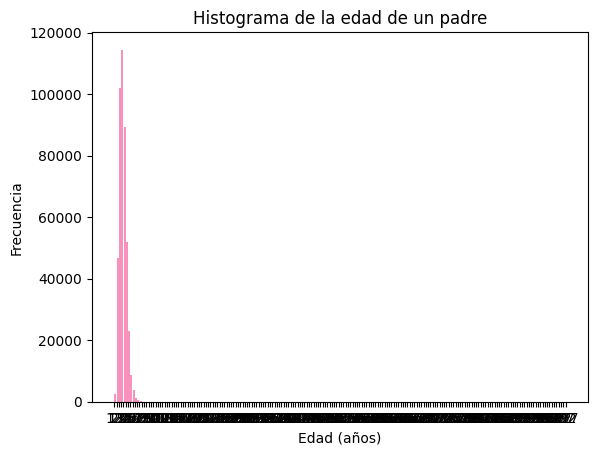

In [4]:
import matplotlib.pyplot as plot

intervalos = range(min(df.EDAD_PADRE), max(df.EDAD_PADRE) + 1, 5)
plot.hist(df.EDAD_PADRE, bins=intervalos, color='#F891BB', rwidth=0.85)
plot.title('Histograma de la edad de un padre')
plot.xlabel('Edad (años)')
plot.ylabel('Frecuencia')
plot.xticks(intervalos)
plot.show()

In [5]:
df1 = tabla[(tabla.EDAD_PADRE < 120) & (tabla.EDAD_MADRE != 99) & (tabla.N_EMB != 99)][["EDAD_PADRE", "EDAD_MADRE", "N_EMB"]]
df1.head(5)

,EDAD_PADRE,EDAD_MADRE,N_EMB
COD_DPTO,,,
76,39,6,2
19,27,4,3
41,28,4,3
50,27,2,1
50,31,4,5


<Axes: xlabel='EDAD_PADRE', ylabel='Density'>

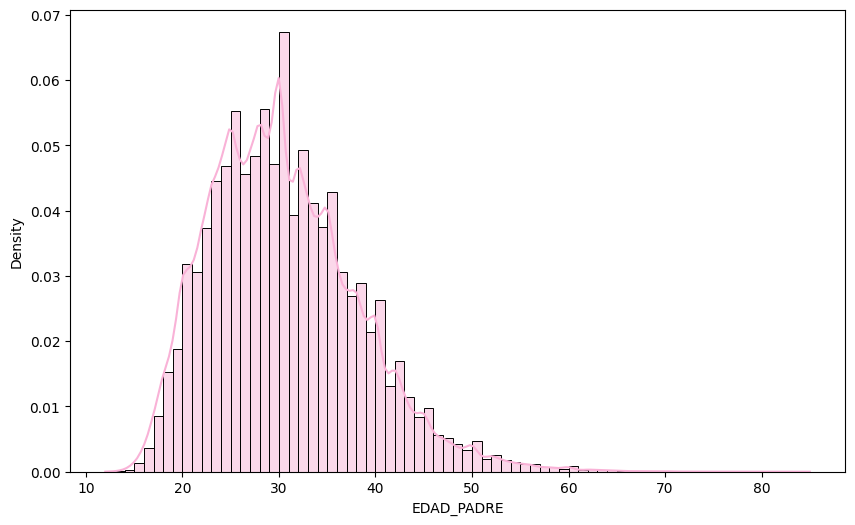

In [6]:
import seaborn as sns
intervalos1 = range(min(df1.EDAD_PADRE), max(df1.EDAD_PADRE) + 1)
plot.figure(figsize=(10, 6))
sns.histplot(x = df1.EDAD_PADRE, bins = intervalos1, kde = True, stat = "density", color = "#F9B2D7", edgecolor='black') # kde = True es la gráfica de la función de densidad de probabilidad estimada por un método Kernel

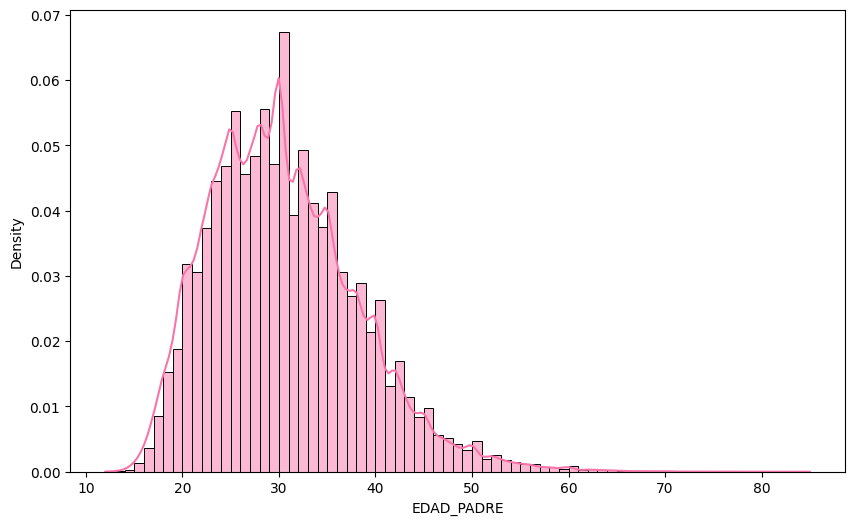

In [7]:
import seaborn as sns
import numpy as np
from scipy.stats import norm
intervalos1 = range(min(df1.EDAD_PADRE), max(df1.EDAD_PADRE) + 1)
plot.figure(figsize=(10, 6))
sns.histplot(x = df1.EDAD_PADRE, bins = intervalos1, kde = True, stat = "density", color = "#F875AA", edgecolor='black') # kde = True es la gráfica de la función de densidad de probabilidad estimada por un método Kernel

xmin, xmax = plot.xlim()
x = np.linspace(xmin, xmax, 1000)
p = norm.pdf(x, np.mean(df1.EDAD_PADRE), np.std(df1.EDAD_PADRE))

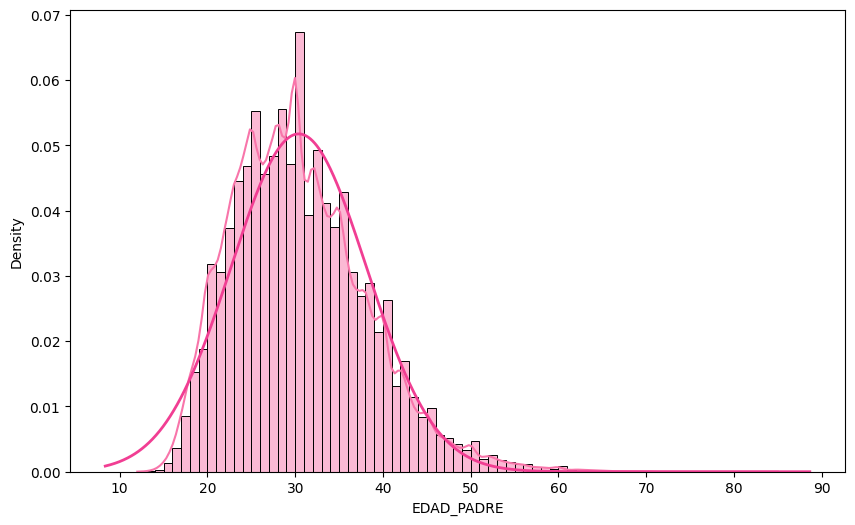

In [8]:
import seaborn as sns
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt
intervalos1 = range(min(df1.EDAD_PADRE), max(df1.EDAD_PADRE) + 1)
plt.figure(figsize=(10, 6))
sns.histplot(x = df1.EDAD_PADRE, bins = intervalos1, kde = True, stat = "density", color = "#F875AA", edgecolor='black') # kde = True es la gráfica de la función de densidad de probabilidad estimada por un método Kernel

xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 1000)
p = norm.pdf(x, np.mean(df1.EDAD_PADRE), np.std(df1.EDAD_PADRE))

plt.plot(x, p, linewidth=2, label='Distribución Normal', color = "#F13E93")

Sea $X:=$ Edad del padre de un recién nacido en Colombia.

Descriptivamente como la función de densidad de probabilidad de los datos estimada por un método Kernel (línea fucsia) no coincide con la función de densidad de probabilidad asumiendo el supuesto de normalidad (línea rosa claro), $X\sim \text{Normal} (\text{Media} = \bar{x}, \text{Varianza} = S^2_x)$, entonces no asumimos normalidad.

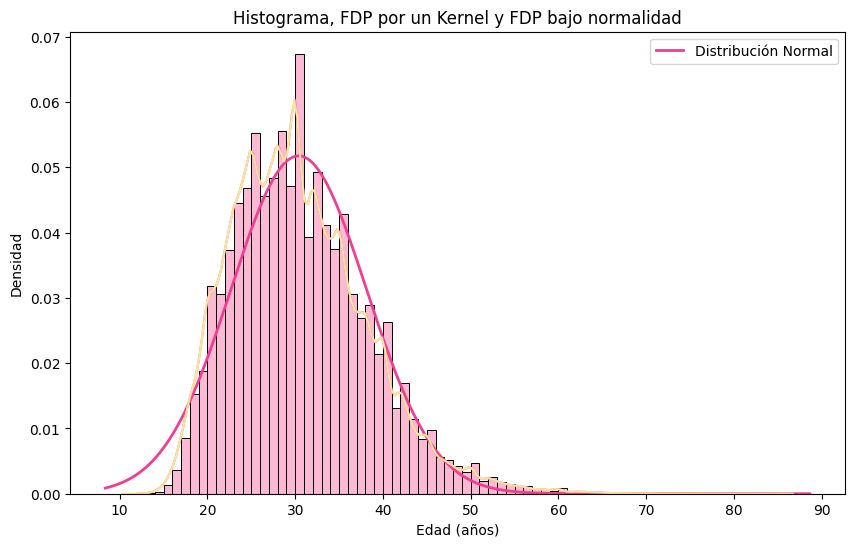

In [9]:

intervalos1 = range(min(df1.EDAD_PADRE), max(df1.EDAD_PADRE) + 1)
plt.figure(figsize=(10, 6))
sns.histplot(x = df1.EDAD_PADRE, bins = intervalos1, kde = True, stat = "density", color = "#F875AA", edgecolor='black') # kde = True es la gráfica de la función de densidad de probabilidad estimada por un método Kernel

xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 1000)
p = norm.pdf(x, np.mean(df1.EDAD_PADRE), np.std(df1.EDAD_PADRE))

plt.plot(x, p, linewidth=2, label='Distribución Normal', color = "#F13E93")
sns.kdeplot(x=df1.EDAD_PADRE, color = "#FCE59A")

plt.title('Histograma, FDP por un Kernel y FDP bajo normalidad')
plt.xlabel('Edad (años)')
plt.ylabel('Densidad')
plt.legend()

# Mostrar el gráfico
plt.show()





In [10]:
from scipy.stats import shapiro
shapiro(df1.EDAD_PADRE)

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 443777.
  res = hypotest_fun_out(*samples, **kwds)


ShapiroResult(statistic=np.float64(0.9677117198585043), pvalue=np.float64(7.6156069148173195e-109))



*   Si el valor p en una prueba de hipótesis es menor que 0.05 se rechaza la hipótesis nula con una confianza del 95%

*  Si el valor p en una prueba de hipótesis es mayor que 0.05 no se rechaza la hipótesis nula con una confianza del 95%

En nuestro caso particular, tenemos que pvalue=0.0 < 0.05, es decir, se rechaza que la variable aleatoria de la edad de un padre de un recién nacido en Colombia presenta distribución normal




In [11]:
df1.EDAD_PADRE.count()
len(df1.EDAD_PADRE)

443777

In [12]:
idx = np.random.randint(len(df1.EDAD_PADRE), size = 100)
shapiro(df1.EDAD_PADRE.index[idx])

ShapiroResult(statistic=np.float64(0.8309182863480176), pvalue=np.float64(2.486453732784109e-09))

Aquí tienes el texto contenido en la imagen:

Como el valor p (igual a $1.10887567827 \times 10^{-7}$) es menor que 0.05, entonces se rechaza que la variable aleatoria de la edad de un padre de un recién nacido en Colombia presenta distribución normal

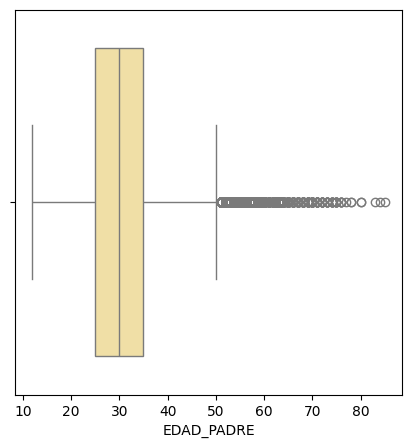

In [13]:
if 'df1' not in globals():
    df1 = tabla[(tabla.EDAD_PADRE < 120) & (tabla.EDAD_MADRE != 99) & (tabla.N_EMB != 99)][["EDAD_PADRE", "EDAD_MADRE", "N_EMB"]]

plt.figure(figsize=(5, 5))
sns.boxplot(x=df1.EDAD_PADRE, color="#FCE59A", saturation=0.75)
plt.show()

Se considera que la edad de un padre de un recién nacido en Colombia es atípica si es mayor que 50 años. El primer cuartil es aproximadamente 25 años, la mediana 30 años y el tercer cuartil 35 años.

Rango intercuartílico = Q₃ − Q₁ = 35 − 25 = 10

In [14]:
fig = px.strip(df1.EDAD_PADRE, orientation = 'h')
fig.show()

De acuerdo con el diagrama de puntos se observa una alta variabilidad de la edad de un padre de un recién nacido en Colombia. Las edades van desde los 12 años hasta aproximadamente los 85 años, y los puntos se vuelven escasos después de los 70 años.

In [15]:
print(f"Media: {np.mean(df1.EDAD_PADRE)}")
print(f"Varianza: {np.var(df1.EDAD_PADRE)} y la desvianción estandar es de {np.std(df1.EDAD_PADRE)}")
print(f"Asimetría: {skew(df1.EDAD_PADRE)}")
print(f"Curtosis: {kurtosis(df1.EDAD_PADRE)}")

Media: 30.399666949841926
Varianza: 59.42512313787833 y la desvianción estandar es de 7.708769236258037
Asimetría: 0.7422600985923384
Curtosis: 0.8607555699997431




*   Aproximadamente el promedio de la edad de un padre de un recién nacido en Colombia es de 30.4 años.

*   Aproximadamente la distancia entre los valores de la edad de un padre de un recién nacido en Colombia y la media es de 7.71 años.

*   La distribución de la edad de un padre de un recién nacido en Colombia es asimétrica positiva, es decir, la media es mayor que la moda de la variable aleatoria.

*   La distribución es leptocúrtica, es decir, hay una mayor concentración de las edades de un padre de un recién nacido en Colombia con respecto a la media.



DIAGRAMA DE DISPERSIÓN Y RECTA DE REGRESIÓN PARA DATOS BIVARIADOS

Vamos a determinar si una variable está correlacionada o si depende de otra

Una variable depende de la otra cuando la ejecución de esta se ve afectada por la variable independiente

Una variable está correlacionada con otra cuando guarda cierta relación pero no es posible hablar de dependencia

Ejemplo: El precio de una vivienda depende del número de habitaciones, ya que entre más habitaciones mayor precio.
Ejemplo: Consumo de arroz y de carne, entre mas arroz se consume, se consume mas carne, ya que se ha visto que al comerse mas arroz se come mas carne. pero no hay una dependencia entre estas dos variables.

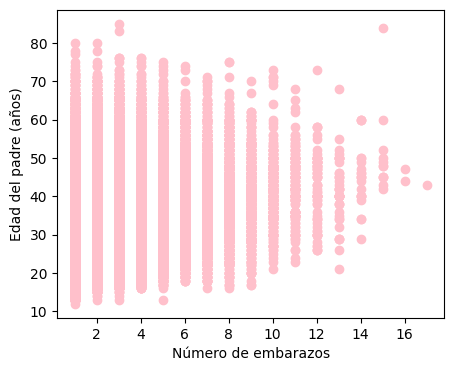

In [16]:
#Diagrama de dispersión
plt.figure(figsize=(5, 4))
plt.scatter(df1["N_EMB"], df1["EDAD_PADRE"], color = "pink", marker = "o")
plt.xlabel('Número de embarazos')
plt.ylabel('Edad del padre (años)')
plt.show()

Se observa en el diagrama de dispersión una nube de puntos sin un patrón claro, lo que sugiere que las variables podrían ser independientes o no estar correlacionadas. Para nuestro ejemplo, el número de embarazos y la edad de un padre en Colombia no muestran una relación evidente a simple vista.


In [17]:
#Modelo de regresión lineal
modelo = LinearRegression()
modelo.fit(np.array(df1.N_EMB).reshape(-1, 1), np.array(df1["EDAD_PADRE"]).reshape(-1, 1))
predi_lineal = modelo.predict(np.array(df1.N_EMB).reshape(-1, 1))
predi_lineal

array([[30.31494332],
       [32.35070055],
       [32.35070055],
       ...,
       [30.31494332],
       [28.27918608],
       [30.31494332]])

La salida corresponde a las edades del padre predichas por el modelo de regresión lineal para cada valor del número de embarazos. Se observa que a mayor número de embarazos, mayor es la edad predicha.

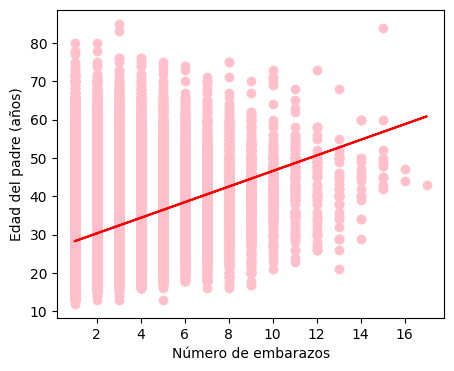

In [18]:
plt.figure(figsize=(5, 4))
plt.scatter(df1["N_EMB"], df1["EDAD_PADRE"], color = "pink", marker = "o")
plt.plot(df1["N_EMB"], predi_lineal, linestyle='-', color = "red")
plt.xlabel('Número de embarazos')
plt.ylabel('Edad del padre (años)')
plt.show()

De acuerdo con la recta de regresión se determina una correlación positiva, es decir, entre más embarazos ha tenido la madre, mayor edad tiende a tener el padre de un recién nacido en Colombia. La variable Y (edad del padre) aumenta cuando aumenta X (número de embarazos).

In [19]:
coef_pearson = np.corrcoef(df1["N_EMB"], df1["EDAD_PADRE"])[0, 1]
coef_spearman, _ = spearmanr(df1["N_EMB"], df1["EDAD_PADRE"])
coef_kendall, _ = kendalltau(df1["N_EMB"], df1["EDAD_PADRE"])
print(f"Los coeficientes de correlación de Pearson, Spearman y Kendall son respectivamente {coef_pearson}, {coef_spearman} y {coef_kendall}.")

Los coeficientes de correlación de Pearson, Spearman y Kendall son respectivamente 0.34003790401915096, 0.3671706831050914 y 0.28723812222507816.


De acuerdo con los coeficientes de correlación de Pearson (0.340), Spearman (0.367) y Kendall (0.287), se determina que el número de embarazos y la edad de un padre de un recién nacido en Colombia están discretamente correlacionados de forma positiva, ya que los tres valores se encuentran entre 0.2 y 0.4.

## 2. Variable N_EMB

Sea $X :=$ número de embarazos, incluido el presente, de la madre de un recién nacido en Colombia (`N_EMB`).
Es una variable cuantitativa **discreta** (un conteo que solo toma valores enteros positivos).

Esta sección usa el DataFrame `df1` (ya limpio) de la parte 1.

### 2.1 Histograma de frecuencias

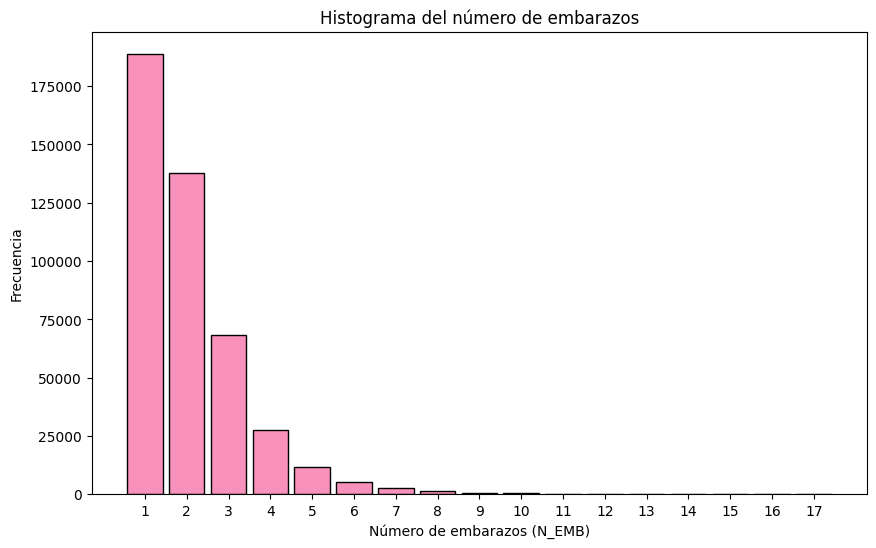

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import norm, shapiro, skew, kurtosis
import plotly.express as px

valores_emb = np.arange(int(df1.N_EMB.min()), int(df1.N_EMB.max()) + 1)

plt.figure(figsize=(10, 6))
# bins centrados en cada entero: así cada barra corresponde a un solo valor de N_EMB
plt.hist(df1.N_EMB, bins=np.arange(valores_emb.min() - 0.5, valores_emb.max() + 1.5),
         color="#F891BB", rwidth=0.85, edgecolor="black")
plt.title("Histograma del número de embarazos")
plt.xlabel("Número de embarazos (N_EMB)")
plt.ylabel("Frecuencia")
plt.xticks(valores_emb)
plt.show()

### 2.2 Histograma, densidad estimada por un kernel y densidad bajo normalidad

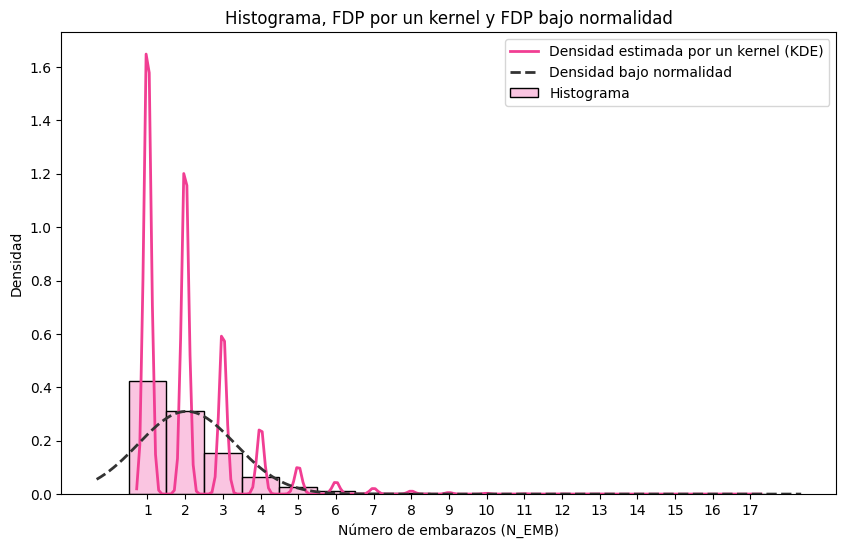

In [21]:
plt.figure(figsize=(10, 6))
sns.histplot(x=df1.N_EMB, discrete=True, stat="density", color="#F9B2D7", edgecolor="black", label="Histograma")
sns.kdeplot(x=df1.N_EMB, color="#F13E93", linewidth=2, label="Densidad estimada por un kernel (KDE)")

xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 1000)
plt.plot(x, norm.pdf(x, df1.N_EMB.mean(), df1.N_EMB.std()), color="#333333", linestyle="--",
         linewidth=2, label="Densidad bajo normalidad")

plt.xticks(valores_emb)
plt.title("Histograma, FDP por un kernel y FDP bajo normalidad")
plt.xlabel("Número de embarazos (N_EMB)")
plt.ylabel("Densidad")
plt.legend()
plt.show()

Descriptivamente, la función de densidad de los datos estimada por un método kernel (línea fucsia) se compara con la función de densidad asumiendo normalidad,
$X \sim \text{Normal}(\text{Media} = \bar{x},\ \text{Varianza} = S_x^2)$ (línea gris discontinua).
Si no coinciden, no asumimos normalidad.
La línea del kernel sale ondulada porque `N_EMB` es discreta (solo toma valores enteros); es normal y no es un error.

### 2.3 Prueba de normalidad (Shapiro-Wilk)

* $H_0$: el número de embarazos se distribuye normal.
* $H_1$: el número de embarazos **no** se distribuye normal.
* Si el valor p es menor que 0.05 se rechaza $H_0$ con una confianza del 95 %; si es mayor, no se rechaza.

Con cientos de miles de datos Shapiro-Wilk no es confiable (scipy avisa que para N > 5000 el valor p puede ser inexacto),
así que se aplica a una muestra aleatoria de 5000 datos (con semilla fija para poder repetir el resultado).

In [22]:
muestra_emb = df1.N_EMB.sample(n=5000, random_state=42)
w_emb, p_emb = shapiro(muestra_emb)
print(f"Estadístico W = {w_emb:.4f} | valor p = {p_emb:.3e}")
if p_emb < 0.05:
    print("Como p < 0.05 se rechaza H0: el número de embarazos NO se distribuye normal.")
else:
    print("Como p >= 0.05 no se rechaza H0: no hay evidencia contra la normalidad.")

Estadístico W = 0.7654 | valor p = 1.228e-64
Como p < 0.05 se rechaza H0: el número de embarazos NO se distribuye normal.


### 2.4 Diagrama de caja y cuartiles

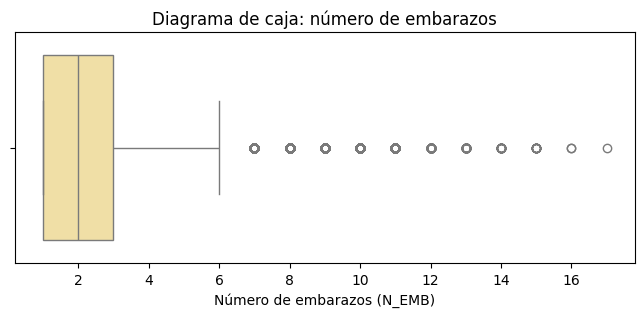

Q1 = 1 | Mediana = 2 | Q3 = 3 | RIC = Q3 - Q1 = 2
Se consideran atípicos los valores menores que -2 o mayores que 6.
Datos atípicos: 4,876 (1.10% del total).


In [23]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=df1.N_EMB, color="#FCE59A", saturation=0.75)
plt.title("Diagrama de caja: número de embarazos")
plt.xlabel("Número de embarazos (N_EMB)")
plt.show()

q1, mediana, q3 = df1.N_EMB.quantile([0.25, 0.5, 0.75])
ric = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * ric, q3 + 1.5 * ric
atipicos = int(((df1.N_EMB < lim_inf) | (df1.N_EMB > lim_sup)).sum())
print(f"Q1 = {q1:g} | Mediana = {mediana:g} | Q3 = {q3:g} | RIC = Q3 - Q1 = {ric:g}")
print(f"Se consideran atípicos los valores menores que {lim_inf:g} o mayores que {lim_sup:g}.")
print(f"Datos atípicos: {atipicos:,} ({atipicos / len(df1):.2%} del total).")

### 2.5 Diagrama de puntos

Se grafica una muestra aleatoria de 5000 datos para que el cuaderno no se vuelva pesado.

In [24]:
fig = px.strip(x=df1.N_EMB.sample(n=5000, random_state=42), title="Diagrama de puntos: número de embarazos (muestra de 5.000 datos)")
fig.update_layout(xaxis_title="N_EMB")
fig.show()
print(f"Con TODOS los datos: mínimo = {df1.N_EMB.min()} y máximo = {df1.N_EMB.max()}.")

Con TODOS los datos: mínimo = 1 y máximo = 17.


### 2.6 Medidas descriptivas

In [25]:
emb = df1.N_EMB
asimetria, curtosis = skew(emb), kurtosis(emb)

print(f"Media: {emb.mean():.4f}")
print(f"Mediana: {emb.median():g}")
print(f"Moda: {emb.mode().iloc[0]:g}")
print(f"Varianza: {emb.var():.4f} y la desviación estándar es de {emb.std():.4f}")
print(f"Mínimo: {emb.min()} | Máximo: {emb.max()}")
print(f"Asimetría: {asimetria:.4f}")
print(f"Curtosis (exceso): {curtosis:.4f}")
print()

if asimetria > 0.1:
    forma_a = "asimétrica positiva (cola larga a la derecha; la media tiende a ser mayor que la mediana y la moda)"
elif asimetria < -0.1:
    forma_a = "asimétrica negativa (cola larga a la izquierda; la media tiende a ser menor que la mediana y la moda)"
else:
    forma_a = "aproximadamente simétrica"
if curtosis > 0.1:
    forma_k = "leptocúrtica (más concentrada alrededor de la media que una normal)"
elif curtosis < -0.1:
    forma_k = "platicúrtica (menos concentrada alrededor de la media que una normal)"
else:
    forma_k = "mesocúrtica (similar a una normal)"

print(f"• En promedio, una madre de un recién nacido en Colombia lleva {emb.mean():.2f} embarazos (incluido el presente).")
print(f"• La distancia típica entre el número de embarazos y la media es de {emb.std():.2f}.")
print(f"• La distribución es {forma_a}.")
print(f"• La distribución es {forma_k}.")
print(f"• Shapiro-Wilk (p = {p_emb:.2e}): {'se rechaza' if p_emb < 0.05 else 'no se rechaza'} que el número de embarazos se distribuya normal.")

Media: 2.0416
Mediana: 2
Moda: 1
Varianza: 1.6580 y la desviación estándar es de 1.2876
Mínimo: 1 | Máximo: 17
Asimetría: 1.9966
Curtosis (exceso): 6.6058

• En promedio, una madre de un recién nacido en Colombia lleva 2.04 embarazos (incluido el presente).
• La distancia típica entre el número de embarazos y la media es de 1.29.
• La distribución es asimétrica positiva (cola larga a la derecha; la media tiende a ser mayor que la mediana y la moda).
• La distribución es leptocúrtica (más concentrada alrededor de la media que una normal).
• Shapiro-Wilk (p = 1.23e-64): se rechaza que el número de embarazos se distribuya normal.
